# De l'image d'un QR code au texte

Ce notebook décode pas à pas le QR code d'une image, en s'appuyant sur le package `basic_qrcode` (dossier `src/`) : chaque étape est une fonction du package, appelée ici avec ses explications.

**Cas traité seulement :** version 2 (25×25 modules), mode « octets ». Les trois autres modes (numérique, alphanumérique, kanji) et les autres versions ne sont pas gérés. Pour la version 2, les quatre niveaux de correction n'utilisent qu'un seul bloc Reed-Solomon, ce qui évite d'avoir à désentrelacer les octets.

> Ce travail s'inspire fortement de la page Wikiversity [Reed–Solomon codes for coders](https://en.wikiversity.org/wiki/Reed%E2%80%93Solomon_codes_for_coders), qui traite le cas de la version 1 : voir le README pour les crédits et la licence.

In [1]:
import numpy as np
from IPython.display import display
from PIL import Image

from basic_qrcode import qr
from basic_qrcode import reed_solomon as rs


def show(modules, scale=12):
    """Affiche un tableau de 0/1 (1 = noir) en gros pixels."""
    img = Image.fromarray(((1 - np.asarray(modules)) * 255).astype(np.uint8))
    return img.resize((img.width * scale, img.height * scale), Image.Resampling.NEAREST)

## 1. Un QR code de test

On le fabrique avec la bibliothèque [segno](https://segno.readthedocs.io/) en fixant tous les paramètres : version 2, niveau de correction L, masque 2, mode octets. Le paramètre `boost_error=False` empêche segno de relever de lui-même le niveau de correction quand il reste de la place.

2-L masque 2


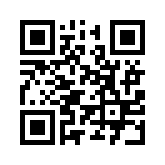

In [2]:
import segno

message = "Mon beau QR code !"
code_test = segno.make_qr(
    message, error="L", boost_error=False, version=2, mask=2, mode="byte"
)
code_test.save("../images/basic_qrcode.png", scale=5)
print(code_test.designator, "masque", code_test.mask)
img = Image.open("../images/basic_qrcode.png")
img

## 2. De l'image au tableau de modules

On passe l'image en niveaux de gris (blanc = 255, noir = 0) puis on binarise au seuil 128. La zone de silence blanche autour du code est inutile : on la supprime en prenant la boîte englobante des pixels noirs.

In [3]:
gray = np.array(img.convert("L"))
dark = gray < 128
ys, xs = np.nonzero(dark)
crop = dark[ys.min() : ys.max() + 1, xs.min() : xs.max() + 1]
print("image :", gray.shape, "-> QR code seul :", crop.shape)

image : (165, 165) -> QR code seul : (125, 125)


La taille d'un module se déduit de la taille du code : en version 2 il y a 25 modules de côté (la formule générale est 4×version + 17). On peut aussi la retrouver avec les motifs de repérage : une ligne qui traverse un de ces gros carrés en son milieu présente la succession de modules noir, blanc, 3 noirs, blanc, noir, soit les longueurs 1-1-3-1-1.

In [4]:
from itertools import groupby

mod_size = crop.shape[0] // 25
row = crop[
    3 * mod_size + mod_size // 2
]  # milieu de la 4e rangée de modules, qui traverse un motif de repérage
runs = [len(list(g)) for _, g in groupby(row)][:5]
print("taille d'un module :", mod_size, "pixels")
print(
    "longueurs des 5 premiers segments / taille d'un module :",
    [r // mod_size for r in runs],
)

taille d'un module : 5 pixels
longueurs des 5 premiers segments / taille d'un module : [1, 1, 3, 1, 1]


On découpe ensuite en 25×25 blocs et chaque module prend la couleur majoritaire de son bloc. C'est ce que fait `image_to_modules` (qui accepte aussi une taille de module non entière).

Attention à la convention : dans l'image le noir vaut 0, alors qu'en QR code un module noir code le bit 1. Le tableau renvoyé suit la convention du QR code (1 = noir).

(25, 25)


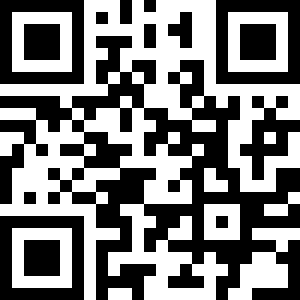

In [5]:
modules = qr.image_to_modules(img)
print(modules.shape)
show(modules)

Vérification : les trois motifs de repérage doivent être là. (Une exception est levée sinon.)

In [6]:
qr.check_finder_patterns(modules)

## 3. Information de format

Deux exemplaires de 15 bits indiquent le niveau de correction d'erreur et le numéro de masque. Ils sont eux-mêmes masqués par un XOR avec une constante, pour éviter un motif tout blanc. On n'en lit qu'un : celui qui entoure le motif de repérage en haut à gauche, en sautant la ligne et la colonne de synchronisation (modules 6).

Les deux premiers bits donnent le niveau de correction, les trois suivants le masque, et les dix derniers servent à corriger le format lui-même par un code BCH. Ce dernier point n'est pas traité ici.

In [7]:
bits = (
    modules[8, :6].tolist()
    + modules[8, 7:9].tolist()
    + [modules[7, 8]]
    + modules[:6, 8][::-1].tolist()
)
brut = "".join(str(b) for b in bits)
demasque = format(int(brut, 2) ^ qr.FORMAT_XOR_MASK, "015b")
print("lu         :", brut)
print("démasqué   :", demasque)
print("niveau     :", demasque[:2], "->", qr.EC_LEVELS[int(demasque[:2], 2)])
print("masque     :", demasque[2:5], "->", int(demasque[2:5], 2))
print()
print(qr.read_format(modules))

lu         : 111110110101010
démasqué   : 010100110111000
niveau     : 01 -> L
masque     : 010 -> 2

('L', 2)


Niveaux de correction en version 2 (source : [qrcode.com](https://www.qrcode.com/en/about/version.html)). Le code complet fait toujours 44 octets, répartis entre données et correction :

| Niveau | Octets de correction | Octets de données | Octets corrigeables |
|---|---|---|---|
| L | 10 | 34 | 5 |
| M | 16 | 28 | 8 |
| Q | 22 | 22 | 11 |
| H | 28 | 16 | 14 |

## 4. Masque

Le masque inverse certains modules selon une formule sur leurs coordonnées (ligne `i`, colonne `j`), pour éviter les grandes zones uniformes et les motifs ressemblant aux repères. Ici, masque 2 : un module sur trois colonnes est inversé. Démasquer, c'est refaire le même XOR.

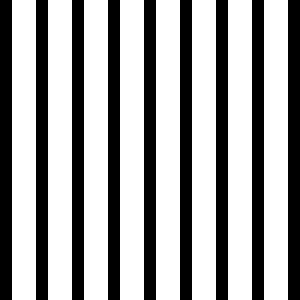

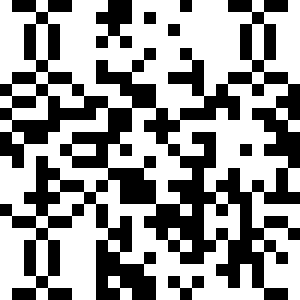

In [8]:
ec_level, mask = qr.read_format(modules)
display(show(qr.mask_matrix(mask)))
unmasked = qr.unmask(modules, mask)
show(unmasked)

Le masque est appliqué à toutes les cases ici, y compris celles qui ne portent pas de données (motifs de repérage, synchronisation...) : sans conséquence, car on ne lira que les cases de données.

## 5. Lecture des octets

Les modules qui ne portent pas de données sont : les motifs de repérage et leurs séparateurs, les lignes de synchronisation, le motif d'alignement (propre à la version 2, centré en (18, 18)) et les deux exemplaires de l'information de format. Il reste 359 modules de données, soit 44 octets et 7 bits de remplissage.

modules de données : 359 = 44 × 8 + 7


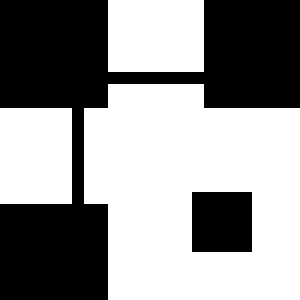

In [9]:
fonction = qr.function_modules()
print("modules de données :", int((1 - fonction).sum()), "=", 44, "× 8 +", 359 - 44 * 8)
show(fonction)

La lecture se fait par bandes de deux colonnes, en partant du coin inférieur droit : on monte en zigzag (colonne de droite, puis de gauche, rangée par rangée), puis on redescend sur la bande suivante, etc., en sautant la colonne de synchronisation. L'image ci-dessous donne l'ordre de lecture des modules de données, du plus clair (premier lu) au plus foncé (dernier lu) ; en gris, les modules de fonction.

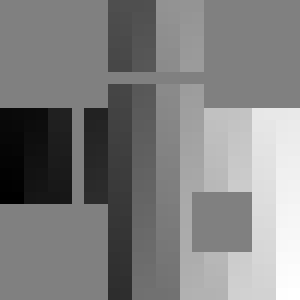

In [10]:
# Astuce : en « lisant » un tableau qui contient l'indice de chaque case, on obtient l'ordre de parcours.
ordre = qr.read_data_bits(np.arange(25 * 25).reshape(25, 25))
degrade = np.full(25 * 25, 128, dtype=np.uint8)
degrade[ordre] = np.linspace(255, 0, len(ordre)).astype(np.uint8)
img_ordre = Image.fromarray(degrade.reshape(25, 25))
img_ordre.resize((300, 300), Image.Resampling.NEAREST)

In [11]:
bits_lus = qr.read_data_bits(unmasked)
codewords = qr.bits_to_codewords(bits_lus)
print(len(bits_lus), "bits ->", len(codewords), "octets")
print(" ".join(f"{b:02X}" for b in codewords))

359 bits -> 44 octets
41 24 D6 F6 E2 06 26 56 17 52 05 15 22 06 36 F6 46 52 02 10 00 EC 11 EC 11 EC 11 EC 11 EC 11 EC 11 EC 74 5C F2 C7 63 A4 33 D4 78 CF


## 6. Correction d'erreur Reed-Solomon

Les 44 octets se découpent en octets de données puis octets de correction (niveau L : 34 + 10). Les octets de correction sont les coefficients du reste de la division du message (vu comme un polynôme) par un polynôme générateur, dans le corps fini à 256 éléments GF(2⁸). Le module `gf256` contient l'arithmétique de ce corps, le module `reed_solomon` le codage et le décodage.

On peut déjà vérifier notre compréhension en recalculant les octets de correction à partir des octets de données : on doit retrouver exactement ceux du QR code.

In [12]:
nsym = qr.EC_CODEWORDS[ec_level]
donnees = codewords[:-nsym]
correction_lue = codewords[-nsym:]
correction_calculee = rs.rs_parity(donnees, nsym)
print("lus      :", " ".join(f"{b:02X}" for b in correction_lue))
print("calculés :", " ".join(f"{b:02X}" for b in correction_calculee))
print("identiques :", correction_lue == correction_calculee)

lus      : 74 5C F2 C7 63 A4 33 D4 78 CF
calculés : 74 5C F2 C7 63 A4 33 D4 78 CF
identiques : True


Pour décoder, on calcule les *syndromes* : la valeur du polynôme du message en α⁰, α¹, ..., α^(nsym−1), qui sont les racines du générateur. Pour un message intact ils sont tous nuls.

In [13]:
print(rs.calc_syndromes(codewords, nsym))

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


Abîmons maintenant le message à la main, en changeant trois octets, pour voir fonctionner le décodeur.

In [14]:
abime = list(codewords)
abime[2] ^= 0x5A
abime[17] ^= 0x01
abime[40] ^= 0xFF
synd = rs.calc_syndromes(abime, nsym)
print("syndromes :", synd)

syndromes : [164, 20, 7, 199, 21, 146, 137, 160, 4, 230]


Les syndromes non nuls contiennent toute l'information sur les erreurs. L'algorithme de **Berlekamp-Massey** en déduit le polynôme localisateur d'erreurs Λ(x), dont le degré est le nombre d'erreurs et dont les racines indiquent où elles se trouvent. On les trouve en essayant toutes les positions (recherche de Chien). Puis la formule de **Forney** donne la valeur à retrancher (XOR) à chaque octet erroné.

In [15]:
lam, nb_erreurs = rs.berlekamp_massey(synd)
print("localisateur :", lam, "-> nombre d'erreurs :", nb_erreurs)

puissances = rs.find_error_powers(lam, len(abime))
positions = sorted(len(abime) - 1 - j for j in puissances)
print("positions des octets erronés :", positions)

localisateur : [1, 218, 28, 94] -> nombre d'erreurs : 3
positions des octets erronés : [2, 17, 40]


In [16]:
valeurs = rs.error_values(synd, lam, puissances)
for j, v in zip(puissances, valeurs):
    i = len(abime) - 1 - j
    print(
        f"octet {i:2d} : erreur {v:02X}  (lu {abime[i]:02X}, corrigé {abime[i] ^ v:02X}, attendu {codewords[i]:02X})"
    )

corrige, positions = rs.rs_decode(abime, nsym)
print("message retrouvé :", corrige == codewords)

octet 40 : erreur FF  (lu CC, corrigé 33, attendu 33)
octet 17 : erreur 01  (lu 53, corrigé 52, attendu 52)
octet  2 : erreur 5A  (lu 8C, corrigé D6, attendu D6)
message retrouvé : True


Jusqu'à `nsym // 2` octets erronés peuvent être corrigés quand on ne sait pas où ils sont (2 équations par erreur : position et valeur). Au-delà, `rs_decode` lève `ReedSolomonError` dans l'immense majorité des cas ; le décodeur peut en théorie aussi « corriger » vers un autre message valide, mais c'est improbable. Voir le notebook `erreurs_et_limites.ipynb`.

Vérification croisée avec la bibliothèque [reedsolo](https://github.com/tomerfiliba-org/reedsolomon) :

In [17]:
import reedsolo

_, mot_complet, _ = reedsolo.RSCodec(nsym).decode(bytes(abime))
list(mot_complet) == corrige

True

## 7. Contenu du message

Les octets de données commencent par 4 bits de **mode** (`0100` = octets) puis 8 bits de **longueur** (nombre de caractères, en version 2 pour le mode octets). Viennent ensuite les caractères, un octet chacun. Après le dernier, la norme prévoit un terminateur de 4 bits à zéro, puis du remplissage par les octets `EC` et `11` en alternance jusqu'à la capacité. Le décodeur n'a pas besoin de lire cette fin : il s'arrête à la longueur annoncée.

In [18]:
bits_donnees = "".join(f"{b:08b}" for b in donnees)
print("mode     :", bits_donnees[:4])
longueur = int(bits_donnees[4:12], 2)
print("longueur :", bits_donnees[4:12], "=", longueur)
print(
    "octets après le message (ici segno met un octet 00 avant le remplissage EC 11 ; qrcode enchaîne directement EC 11) :"
)
print(" ".join(f"{b:02X}" for b in donnees[longueur + 2 :]))
print()
qr.parse_byte_mode(donnees)

mode     : 0100
longueur : 00010010 = 18
octets après le message (ici segno met un octet 00 avant le remplissage EC 11 ; qrcode enchaîne directement EC 11) :
00 EC 11 EC 11 EC 11 EC 11 EC 11 EC 11 EC



b'Mon beau QR code !'

## 8. Tout en un

`decode_image` enchaîne toutes ces étapes.

In [19]:
from basic_qrcode import decode_image

resultat = decode_image("../images/basic_qrcode.png")
resultat

DecodedQR(data=b'Mon beau QR code !', ec_level='L', mask=2, corrected=())

In [20]:
resultat.text

'Mon beau QR code !'

## Pour aller plus loin

- [Reed–Solomon codes for coders](https://en.wikiversity.org/wiki/Reed%E2%80%93Solomon_codes_for_coders) (Wikiversity) : présentation complète, avec le cas de la version 1, la correction du format par code BCH et la correction des effacements.
- [Berlekamp-Massey, sur le blog cp-blog](https://mzhang2021.github.io/cp-blog/berlekamp-massey/) : présentation de l'algorithme.
- [ramrsbd](https://github.com/littlefs-project/ramrsbd) (littlefs) : implémentation de Reed-Solomon, avec une explication détaillée de l'algorithme.
- [Tableaux des versions et capacités](https://www.qrcode.com/en/about/version.html) (qrcode.com).